In [3]:
last_session = "ppo_train_2710_RGB_death_penalty_40_step_penalty_01"
current_session = "ppo_train_2710_RGB_death_penalty_40_step_penalty_01"

In [5]:
from pacman_rl import PPOConfig, train_ppo, get_device
from pacman_rl.runs import load_run, save_run
from functools import partial
from pacman_rl.envs import log_reward

def log_reward_with_step_penalty(r, step_penalty):
    return log_reward(r) - step_penalty
# Thử nghiệm với death_penalty = 40 và step_penalty = 0.1, train trên
# 10_000_000 steps
device = get_device()
cfg = PPOConfig(
    total_steps=10_000_000, 
    lr=2.5e-4,
    seed=0,
    save_every=50_000,
    death_penalty=40,
    n_envs=32,
    n_steps=512,
    n_minibatches=4,
    reward_fn=partial(log_reward_with_step_penalty, step_penalty=0.1),
    rgb_scale=True
    )

ppo = load_run("runs",f"{last_session}", "ppo", device=device)
result = train_ppo(cfg=cfg, model=ppo.model, save_path=f"runs/{current_session}.pt", device=device)

# result = train_ppo(cfg=cfg, model=None, save_path=f"runs/{current_session}.pt", device=device)

save_run(result, "runs", current_session, append=True)

PPO: 610 updates x 16384 mẫu = 9,994,240 bước, 32 env song song
Update 50/610 | step 819,200 | avg score(20) 590 | 3725 lượt | 220 bước/lượt | 0.35 viên NL/lượt | 0.20 ma/lượt | entropy 1.480 | KL 0.0049 | clipfrac 0.182 | 2887 steps/s
Update 100/610 | step 1,638,400 | avg score(20) 590 | 3717 lượt | 220 bước/lượt | 0.34 viên NL/lượt | 0.23 ma/lượt | entropy 1.584 | KL 0.0028 | clipfrac 0.030 | 2814 steps/s
Update 150/610 | step 2,457,600 | avg score(20) 738 | 3722 lượt | 220 bước/lượt | 0.34 viên NL/lượt | 0.21 ma/lượt | entropy 1.599 | KL 0.0012 | clipfrac 0.044 | 2784 steps/s
Update 200/610 | step 3,276,800 | avg score(20) 542 | 3699 lượt | 221 bước/lượt | 0.35 viên NL/lượt | 0.23 ma/lượt | entropy 1.579 | KL 0.0027 | clipfrac 0.127 | 2767 steps/s
Update 250/610 | step 4,096,000 | avg score(20) 691 | 3666 lượt | 223 bước/lượt | 0.34 viên NL/lượt | 0.22 ma/lượt | entropy 1.492 | KL -0.0007 | clipfrac 0.041 | 2749 steps/s
Update 300/610 | step 4,915,200 | avg score(20) 606 | 3714 lượt

c:\Users\LENOVO\miniconda3\envs\rel_pacman\lib\site-packages\gymnasium\vector\async_vector_env.py:460: UserWarning: WARN: Calling `close` while waiting for a pending call to `step` to complete.
  logger.warn(


(WindowsPath('runs/ppo_train_2710_RGB_death_penalty_40_step_penalty_01.pt'),
 WindowsPath('runs/ppo_train_2710_RGB_death_penalty_40_step_penalty_01_episodes.npy'),
 WindowsPath('runs/ppo_train_2710_RGB_death_penalty_40_step_penalty_01_log.npy'))

In [2]:
from pacman_rl import evaluate, watch, dqn_policy
from pacman_rl.plotting import plot_eval
from pacman_rl import random_baseline
from pacman_rl.evaluation import ppo_policy
from pacman_rl import get_device
from pacman_rl.runs import load_run
device = get_device()

load_session = load_run("runs", f"{current_session}", "ppo", device=device)
act_session = ppo_policy(load_session.model, device)              # greedy=True: luôn chọn action tốt nhất

load_last_session = load_run("runs", f"{last_session}", "ppo", device=device)
act_last_session = ppo_policy(load_last_session.model, device)              # greedy=True: luôn chọn action tốt nhất

# plot_eval({"Random": random_baseline(5),
#            "Last PPO": evaluate(act_last_session, n_episodes=10),
#            "Current PPO": evaluate(act_session, n_episodes=10),  # seed cố định 1000..1009, công bằng giữa các phương pháp
#            })

watch(act_session, episodes=2)                           # mở cửa sổ game, cần màn hình


[play] ván 1: 300 điểm (635 bước)
[play] ván 2: 300 điểm (595 bước)


[300.0, 300.0]

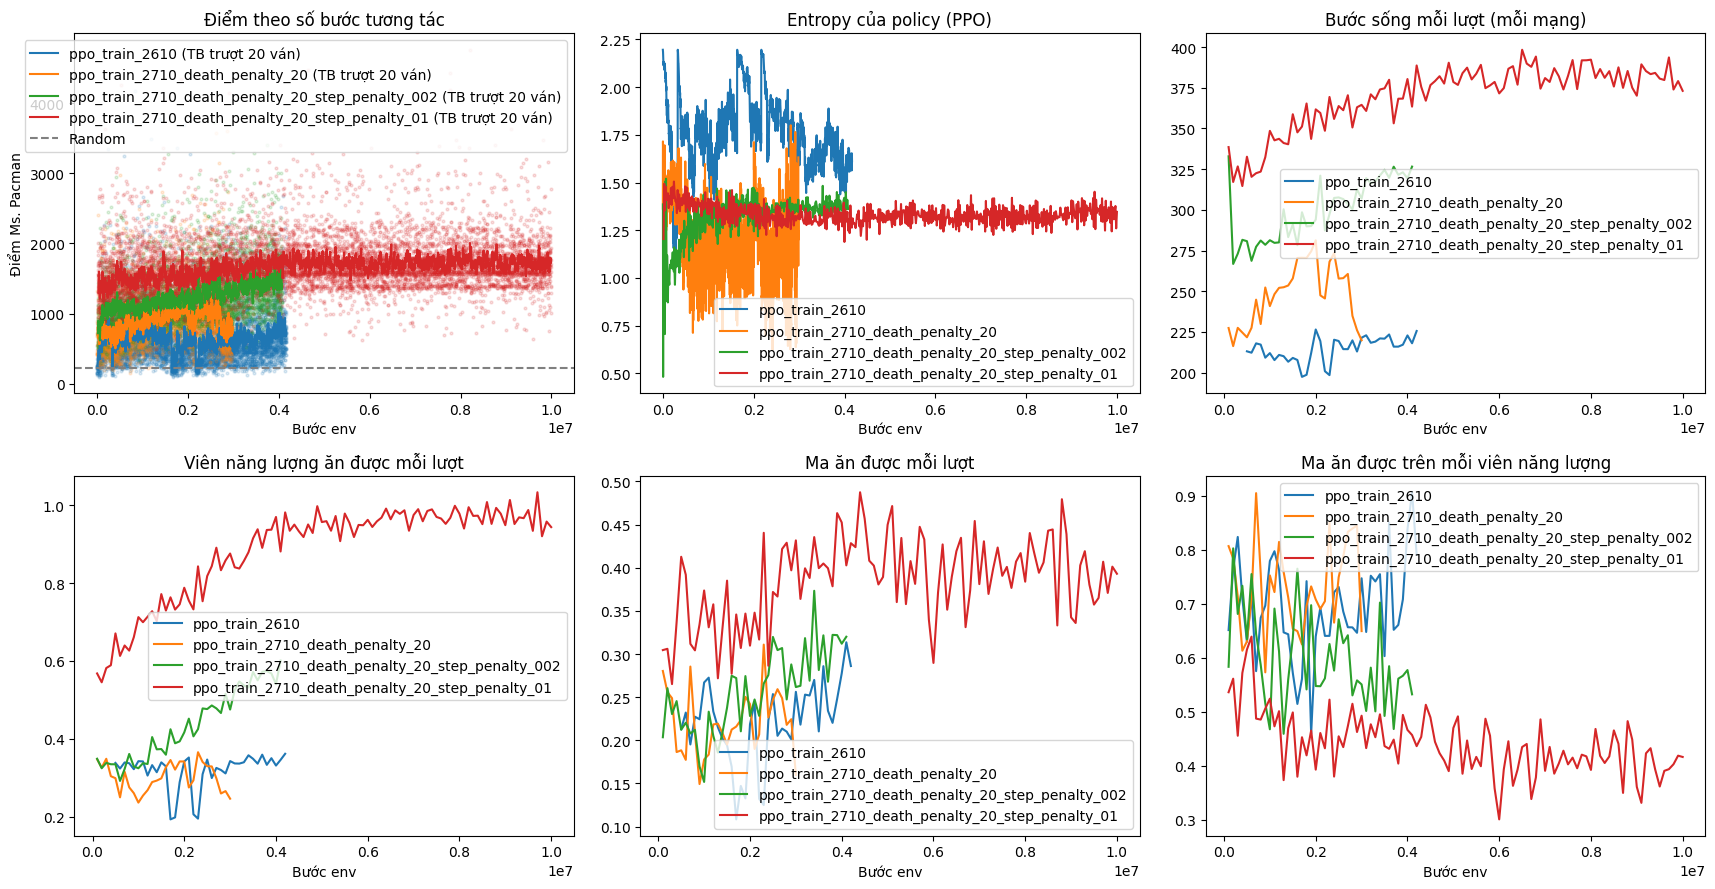

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


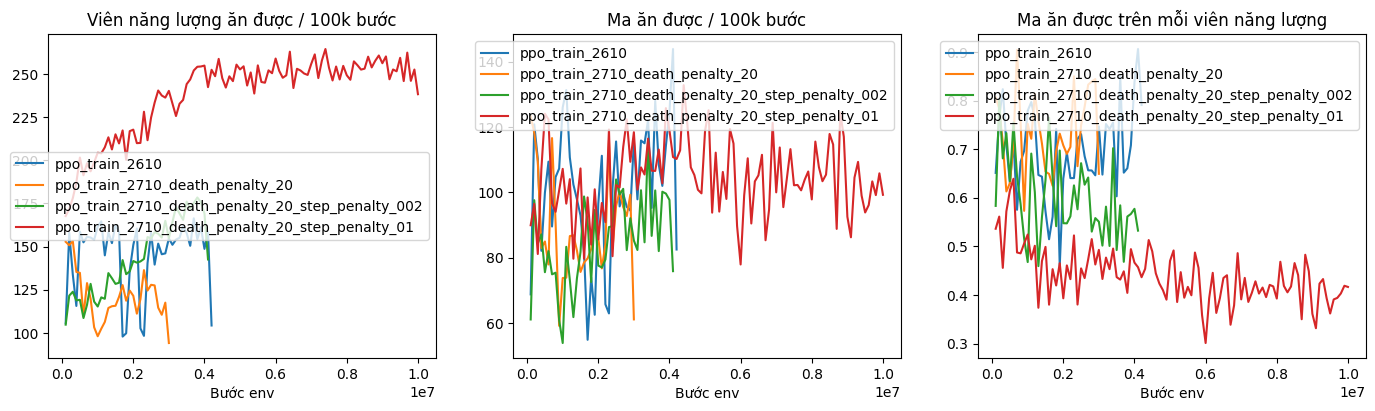

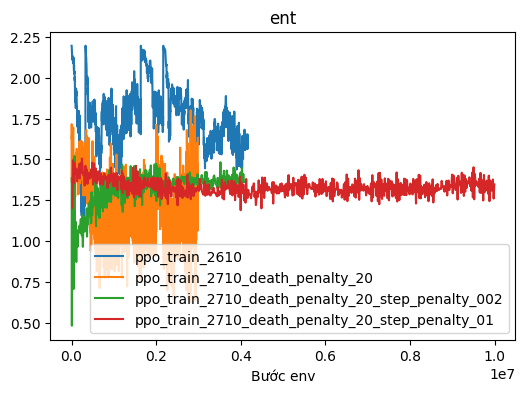

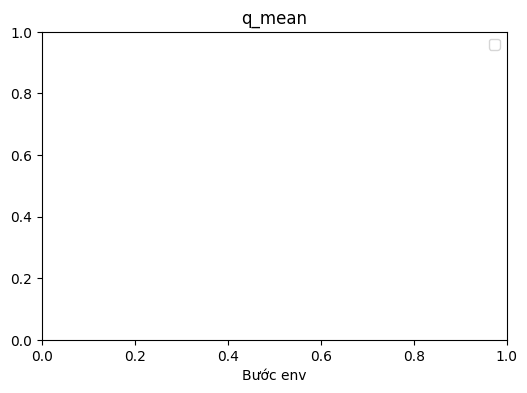

In [3]:
from pacman_rl.plotting import compare
from pacman_rl import random_baseline, get_device
device = get_device()
runs = compare(
    ["ppo_train_2610", 
     "ppo_train_2710_death_penalty_20",
     "ppo_train_2710_death_penalty_20_step_penalty_002",
     "ppo_train_2710_death_penalty_20_step_penalty_01"], 
               directory="runs",
               random_scores=random_baseline(5),
               metrics=("ent", "q_mean"),
               device=device,
               save_path="runs/27-10.png")

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


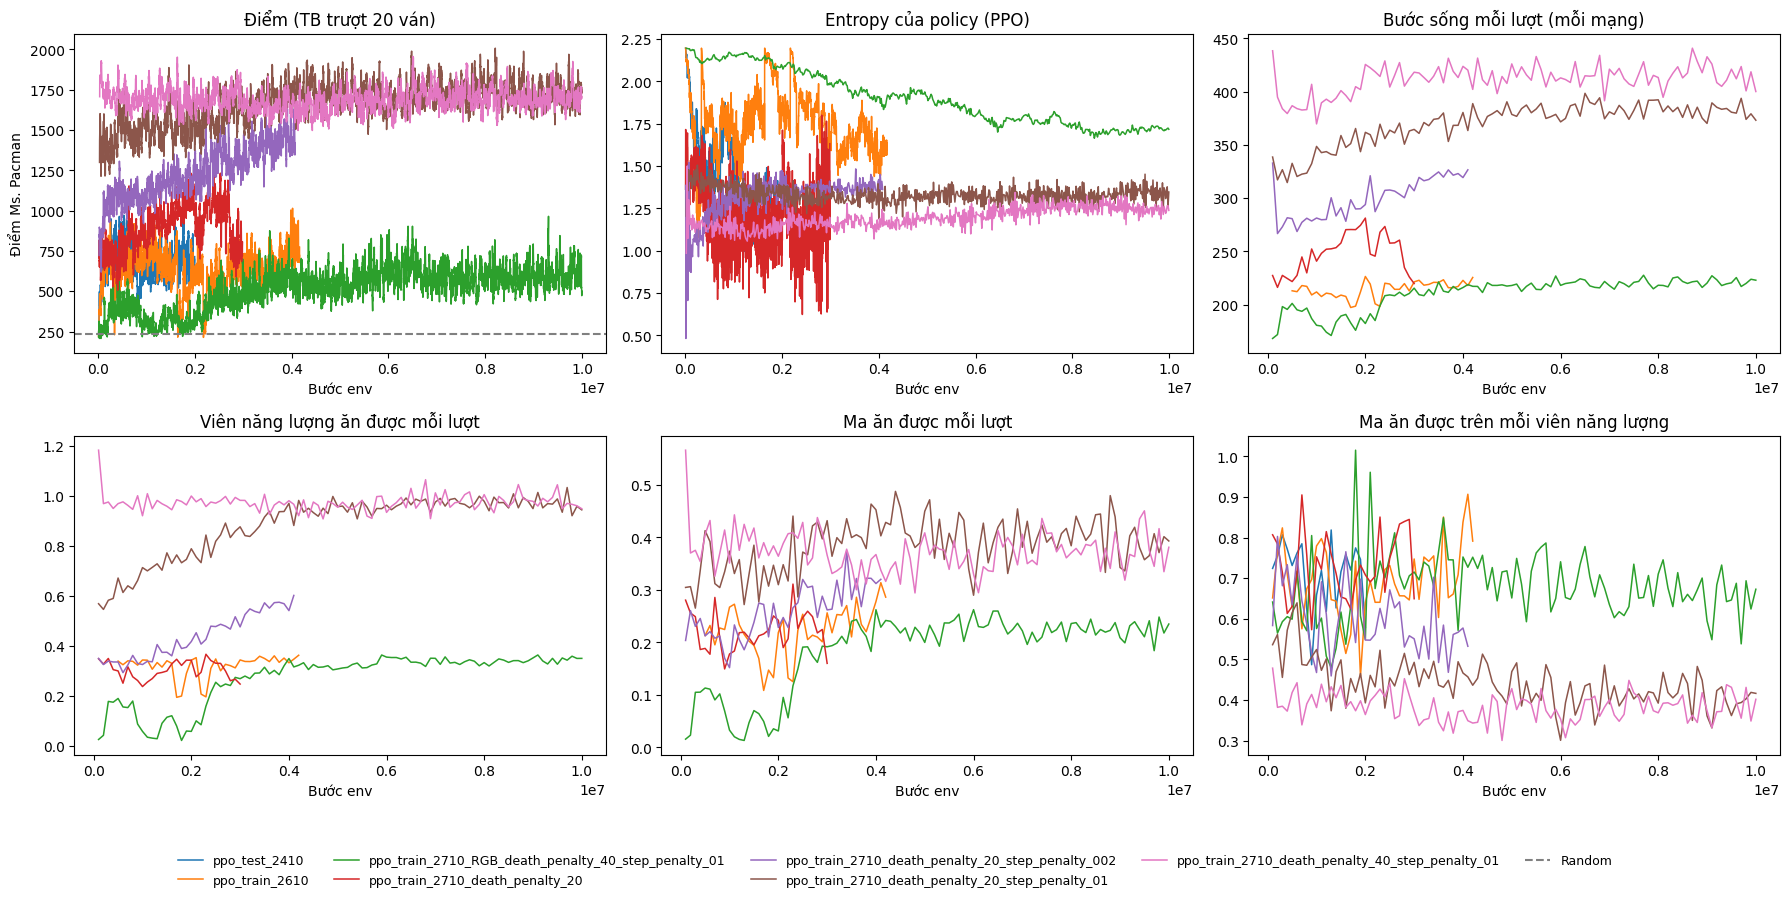

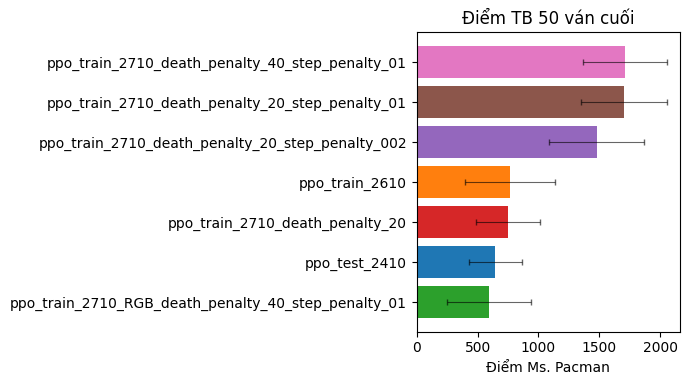

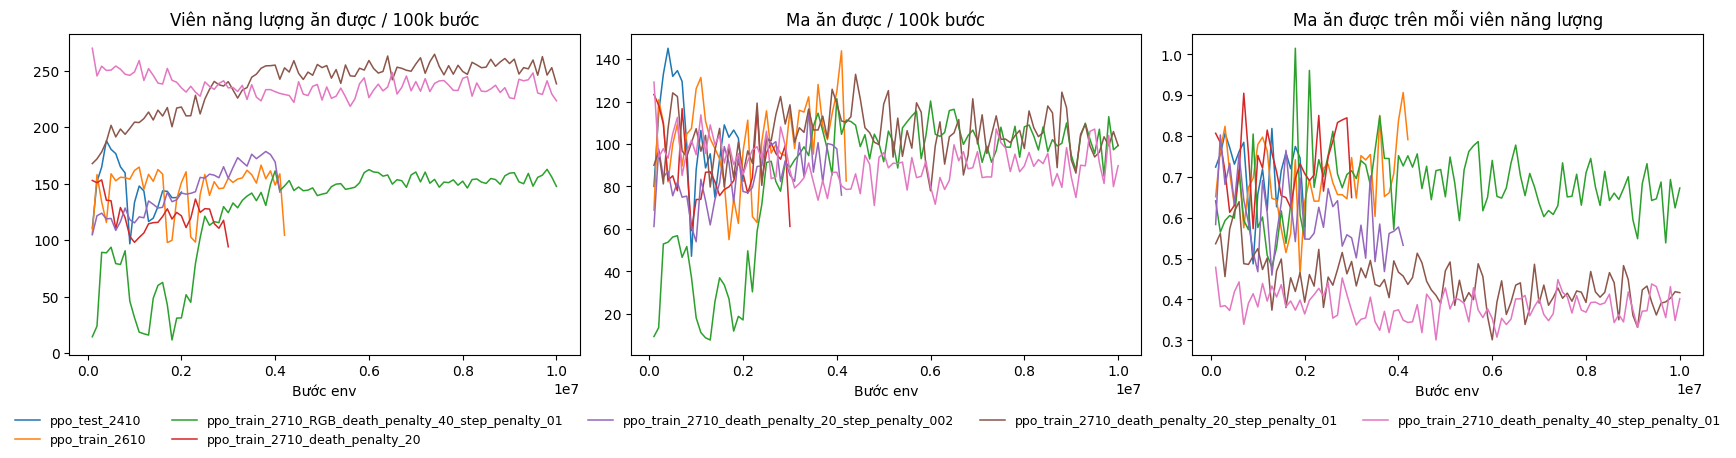

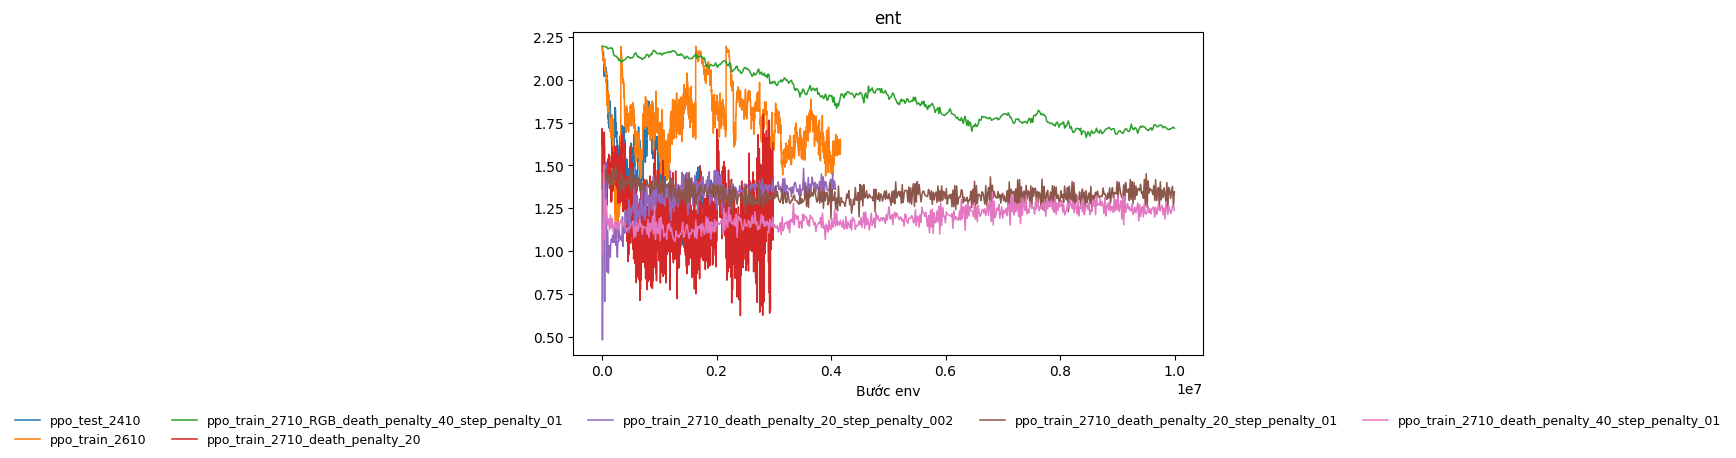

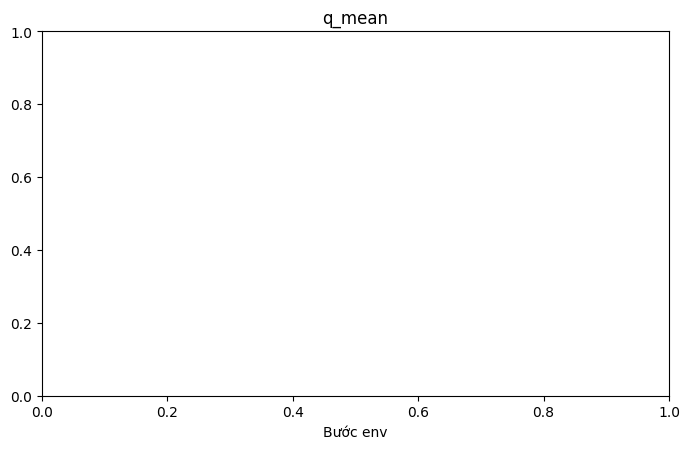

In [2]:
from pacman_rl.plotting import compare
from pacman_rl import random_baseline, get_device
device = get_device()
runs = compare(directory="runs",
               random_scores=random_baseline(5),
               metrics=("ent", "q_mean"),
               device=device,
               save_path="runs/27-10.png")